## 1.Environment Setup

In [1]:
# Import thư viện cần thiết
import os
import random
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_score

warnings.filterwarnings('ignore')

# Đặt seed để đảm bảo kết quả nhất quán giữa các lần chạy
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
np.random.seed(SEED)
random.seed(SEED)
print(f"Seed: {SEED}")

Seed: 42


## 2. Data Processing

Run `[Solution]_Create_Datasets.ipynb` first after placing the source `heart.csv` in `Data/`. It writes the processed CSV splits locally. In Colab, clone the repository and run the preparation notebook from the repository root.

In [ ]:
# Use the processed CSV files included in the repository's Data/ folder.
from pathlib import Path

DATA_DIR = Path('../Data')
if not DATA_DIR.is_dir():
    DATA_DIR = Path('Data')
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        'Clone the heart-disease-classification repository, then run this notebook '
        'from the repository root or its Solution/ folder.'
    )
print(f'Using data from: {DATA_DIR.resolve()}')

In [3]:
def read_csv(file_path):
    df = pd.read_csv(DATA_DIR / Path(file_path).name)
    display(df.head())

    X = df.drop('target', axis=1)
    y = df['target']
    display(y.value_counts())

    print("Shape df: ", df.shape)
    print("Shape X: ", X.shape)
    print("Shape y: ", y.shape)

    return X, y

### 2.1 Original Dataset

In [4]:
X_train, y_train = read_csv('Data/raw_train.csv')
X_val, y_val = read_csv('Data/raw_val.csv')
X_test, y_test = read_csv('Data/raw_test.csv')

,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal,target
0,-0.729485,-0.395692,0.458139,0.708371,-0.445445,1.0,1.000000,0.0,1.0,0.0,0.5,0.000000,1.0,1
1,0.050166,-0.054513,0.230598,0.222495,-0.891627,1.0,0.333333,0.0,0.0,0.0,0.0,0.000000,0.0,0
2,-0.061212,0.059213,0.723605,0.399178,-0.891627,0.0,0.333333,1.0,1.0,1.0,0.0,0.333333,0.0,0
3,-0.061212,-1.305501,1.121803,0.266666,-0.891627,1.0,0.333333,0.0,0.0,0.0,0.0,0.000000,1.0,0
4,0.272924,0.514117,-0.167601,-1.190962,-0.713154,0.0,1.000000,0.0,0.0,1.0,0.5,0.000000,1.0,1


,count
target,
0,131
1,111


Shape df:  (242, 14)
Shape X:  (242, 13)
Shape y:  (242,)


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal,target
0,-1.063621,0.400391,-0.262410,0.089984,-0.713154,0.0,1.000000,0.0,1.0,1.0,0.5,0.0,0.0,0
1,1.720848,-0.054513,1.368307,-1.809349,1.250048,1.0,1.000000,0.0,1.0,0.0,0.5,1.0,0.0,1
2,-0.061212,1.082748,-0.338257,0.664201,0.536156,1.0,0.666667,0.0,1.0,0.0,0.0,0.0,1.0,0
3,0.941197,0.229802,0.040979,0.973394,-0.891627,0.0,0.666667,0.0,1.0,0.0,0.0,0.0,0.0,0
4,0.495681,0.229802,-0.300333,0.487519,-0.445445,1.0,1.000000,0.0,0.0,0.0,0.5,0.0,1.0,0


,count
target,
0,16
1,14


Shape df:  (30, 14)
Shape X:  (30, 13)
Shape y:  (30,)


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal,target
0,0.384303,-0.168240,-0.641646,-0.837597,1.071575,1.0,1.000000,0.0,1.0,1.0,0.5,1.0,1.0,1
1,-2.288787,-0.736870,-1.286348,1.061736,-0.891627,1.0,0.000000,0.0,1.0,0.0,0.0,0.0,0.0,0
2,0.829818,-0.054513,-0.357219,-0.175039,0.714629,1.0,0.666667,0.0,0.0,0.0,0.5,1.0,1.0,0
3,-0.395349,-0.054513,0.116827,-0.042528,-0.445445,0.0,0.666667,0.0,1.0,0.0,0.0,0.0,0.0,0
4,-1.397757,-0.623144,-0.186562,1.945146,-0.177735,1.0,0.666667,1.0,0.0,0.0,1.0,0.0,1.0,0


,count
target,
0,17
1,14


Shape df:  (31, 14)
Shape X:  (31, 13)
Shape y:  (31,)


### 2.2 FE Dataset

In [5]:
X_fe_train, y_fe_train = read_csv('Data/fe_train.csv')
X_fe_val, y_fe_val = read_csv('Data/fe_val.csv')
X_fe_test, y_fe_test = read_csv('Data/fe_test.csv')

,thal_3.0,thal_7.0,cp_4.0,ca_0.0,exang_1.0,exang_0.0,oldpeak,slope_1.0,chol,slope_2.0,thalach,hr_ratio,sex_1.0,target
0,0.0,1.0,1.0,1.0,0.0,1.0,-0.445445,0.0,0.458139,1.0,0.708371,0.726265,1.0,1
1,1.0,0.0,0.0,1.0,0.0,1.0,-0.891627,1.0,0.230598,0.0,0.222495,-0.054469,1.0,0
2,1.0,0.0,0.0,0.0,1.0,0.0,-0.891627,1.0,0.723605,0.0,0.399178,0.099522,0.0,0
3,0.0,1.0,0.0,1.0,0.0,1.0,-0.891627,1.0,1.121803,0.0,0.266666,0.031766,1.0,0
4,0.0,1.0,1.0,1.0,1.0,0.0,-0.713154,0.0,-0.167601,1.0,-1.190962,-0.859761,0.0,1


,count
target,
0,131
1,111


Shape df:  (242, 14)
Shape X:  (242, 13)
Shape y:  (242,)


,thal_3.0,thal_7.0,cp_4.0,ca_0.0,exang_1.0,exang_0.0,oldpeak,slope_1.0,chol,slope_2.0,thalach,hr_ratio,sex_1.0,target
0,1.0,0.0,1.0,1.0,1.0,0.0,-0.713154,0.0,-0.262410,1.0,0.089984,0.628019,0.0,0
1,1.0,0.0,1.0,0.0,0.0,1.0,1.250048,0.0,1.368307,1.0,-1.809349,-1.592443,1.0,1
2,0.0,1.0,0.0,1.0,0.0,1.0,0.536156,1.0,-0.338257,0.0,0.664201,0.235034,1.0,0
3,1.0,0.0,0.0,1.0,0.0,1.0,-0.891627,1.0,0.040979,0.0,0.973394,-0.161823,0.0,0
4,0.0,1.0,1.0,1.0,0.0,1.0,-0.445445,0.0,-0.300333,1.0,0.487519,-0.163464,1.0,0


,count
target,
0,16
1,14


Shape df:  (30, 14)
Shape X:  (30, 13)
Shape y:  (30,)


,thal_3.0,thal_7.0,cp_4.0,ca_0.0,exang_1.0,exang_0.0,oldpeak,slope_1.0,chol,slope_2.0,thalach,hr_ratio,sex_1.0,target
0,0.0,1.0,1.0,0.0,1.0,0.0,1.071575,0.0,-0.641646,1.0,-0.837597,-0.736915,1.0,1
1,1.0,0.0,0.0,1.0,0.0,1.0,-0.891627,1.0,-1.286348,0.0,1.061736,2.749978,1.0,0
2,0.0,1.0,0.0,0.0,0.0,1.0,0.714629,0.0,-0.357219,1.0,-0.175039,-0.619566,1.0,0
3,1.0,0.0,0.0,1.0,0.0,1.0,-0.445445,1.0,0.116827,0.0,-0.042528,0.071622,0.0,0
4,0.0,1.0,0.0,1.0,0.0,1.0,-0.177735,0.0,-0.186562,0.0,1.945146,2.141882,1.0,0


,count
target,
0,17
1,14


Shape df:  (31, 14)
Shape X:  (31, 13)
Shape y:  (31,)


### 2.3 Original + DT Dataset

In [6]:
X_dt_train, y_dt_train = read_csv('Data/dt_train.csv')
X_dt_val, y_dt_val = read_csv('Data/dt_val.csv')
X_dt_test, y_dt_test = read_csv('Data/dt_test.csv')

,thal,cp,ca,oldpeak,chol,age,thalach,sex,slope,exang,target
0,1.0,1.000000,0.000000,-0.445445,0.458139,-0.729485,0.708371,1.0,0.5,0.0,1
1,0.0,0.333333,0.000000,-0.891627,0.230598,0.050166,0.222495,1.0,0.0,0.0,0
2,0.0,0.333333,0.333333,-0.891627,0.723605,-0.061212,0.399178,0.0,0.0,1.0,0
3,1.0,0.333333,0.000000,-0.891627,1.121803,-0.061212,0.266666,1.0,0.0,0.0,0
4,1.0,1.000000,0.000000,-0.713154,-0.167601,0.272924,-1.190962,0.0,0.5,1.0,1


,count
target,
0,131
1,111


Shape df:  (242, 11)
Shape X:  (242, 10)
Shape y:  (242,)


,thal,cp,ca,oldpeak,chol,age,thalach,sex,slope,exang,target
0,0.0,1.000000,0.0,-0.713154,-0.262410,-1.063621,0.089984,0.0,0.5,1.0,0
1,0.0,1.000000,1.0,1.250048,1.368307,1.720848,-1.809349,1.0,0.5,0.0,1
2,1.0,0.666667,0.0,0.536156,-0.338257,-0.061212,0.664201,1.0,0.0,0.0,0
3,0.0,0.666667,0.0,-0.891627,0.040979,0.941197,0.973394,0.0,0.0,0.0,0
4,1.0,1.000000,0.0,-0.445445,-0.300333,0.495681,0.487519,1.0,0.5,0.0,0


,count
target,
0,16
1,14


Shape df:  (30, 11)
Shape X:  (30, 10)
Shape y:  (30,)


,thal,cp,ca,oldpeak,chol,age,thalach,sex,slope,exang,target
0,1.0,1.000000,1.0,1.071575,-0.641646,0.384303,-0.837597,1.0,0.5,1.0,1
1,0.0,0.000000,0.0,-0.891627,-1.286348,-2.288787,1.061736,1.0,0.0,0.0,0
2,1.0,0.666667,1.0,0.714629,-0.357219,0.829818,-0.175039,1.0,0.5,0.0,0
3,0.0,0.666667,0.0,-0.445445,0.116827,-0.395349,-0.042528,0.0,0.0,0.0,0
4,1.0,0.666667,0.0,-0.177735,-0.186562,-1.397757,1.945146,1.0,1.0,0.0,0


,count
target,
0,17
1,14


Shape df:  (31, 11)
Shape X:  (31, 10)
Shape y:  (31,)


### 2.4 FE + DT Dataset

In [7]:
X_fe_dt_train, y_fe_dt_train = read_csv('Data/fe_dt_train.csv')
X_fe_dt_val, y_fe_dt_val = read_csv('Data/fe_dt_val.csv')
X_fe_dt_test, y_fe_dt_test = read_csv('Data/fe_dt_test.csv')

,thal_3.0,cp_4.0,ca_0.0,chol_per_age,hr_ratio,oldpeak,chol,age,exang_0.0,cp_3.0,target
0,0.0,1.0,1.0,0.952258,0.726265,-0.445445,0.458139,-0.729485,1.0,0.0,1
1,1.0,0.0,1.0,0.082082,-0.054469,-0.891627,0.230598,0.050166,1.0,0.0,0
2,1.0,0.0,0.0,0.606839,0.099522,-0.891627,0.723605,-0.061212,0.0,0.0,0
3,0.0,0.0,1.0,0.965051,0.031766,-0.891627,1.121803,-0.061212,1.0,0.0,0
4,0.0,1.0,1.0,-0.411237,-0.859761,-0.713154,-0.167601,0.272924,0.0,0.0,1


,count
target,
0,131
1,111


Shape df:  (242, 11)
Shape X:  (242, 10)
Shape y:  (242,)


,thal_3.0,cp_4.0,ca_0.0,chol_per_age,hr_ratio,oldpeak,chol,age,exang_0.0,cp_3.0,target
0,1.0,1.0,1.0,0.524962,0.628019,-0.713154,-0.262410,-1.063621,0.0,0.0,0
1,1.0,1.0,0.0,-0.068646,-1.592443,1.250048,1.368307,1.720848,1.0,0.0,1
2,0.0,0.0,1.0,-0.348393,0.235034,0.536156,-0.338257,-0.061212,1.0,1.0,0
3,1.0,0.0,1.0,-0.621316,-0.161823,-0.891627,0.040979,0.941197,1.0,1.0,0
4,0.0,1.0,1.0,-0.652540,-0.163464,-0.445445,-0.300333,0.495681,1.0,0.0,0


,count
target,
0,16
1,14


Shape df:  (30, 11)
Shape X:  (30, 10)
Shape y:  (30,)


,thal_3.0,cp_4.0,ca_0.0,chol_per_age,hr_ratio,oldpeak,chol,age,exang_0.0,cp_3.0,target
0,0.0,1.0,0.0,-0.875417,-0.736915,1.071575,-0.641646,0.384303,0.0,0.0,1
1,1.0,0.0,1.0,0.624900,2.749978,-0.891627,-1.286348,-2.288787,1.0,0.0,0
2,0.0,0.0,0.0,-0.873880,-0.619566,0.714629,-0.357219,0.829818,1.0,1.0,0
3,1.0,0.0,1.0,0.317862,0.071622,-0.445445,0.116827,-0.395349,1.0,1.0,0
4,0.0,0.0,1.0,0.957741,2.141882,-0.177735,-0.186562,-1.397757,1.0,1.0,0


,count
target,
0,17
1,14


Shape df:  (31, 11)
Shape X:  (31, 10)
Shape y:  (31,)


## 3.Random Forest (RF)

In [8]:
def find_optimal_rf(
    X_train, y_train, n_estimators_range=range(50, 501, 50),
    cv_splits=3, max_depth=5, min_samples_split=2, min_samples_leaf=1,
    max_features="sqrt", bootstrap=True, class_weight=None
):
    cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=SEED)
    scores = []

    for n in n_estimators_range:
        rf = RandomForestClassifier(
            n_estimators=n,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            bootstrap=bootstrap,
            class_weight=class_weight,
            n_jobs=-1,
            random_state=SEED
        )
        cv_score = cross_val_score(
            rf, X_train, y_train,
            cv=cv, scoring='accuracy', n_jobs=-1
        )
        scores.append(cv_score.mean())

    # Lấy n_estimators tối ưu
    best_n = list(n_estimators_range)[int(np.argmax(scores))]
    print(f"n_estimators tối ưu (CV): {best_n}")

    # Vẽ biểu đồ chọn n_estimators theo CV
    plt.figure(figsize=(10, 6))
    plt.plot(list(n_estimators_range), scores, 'bo-')
    plt.title(f'Chọn n_estimators tối ưu cho Random Forest (CV={cv_splits}-fold)')
    plt.xlabel('n_estimators')
    plt.ylabel('Cross-Validation Accuracy')
    plt.grid(True)
    plt.savefig("rf.pdf", bbox_inches="tight")
    plt.show()

    # Train lại với toàn bộ X_train
    best_model = RandomForestClassifier(
        n_estimators=best_n, max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        bootstrap=bootstrap,
        class_weight=class_weight,
        n_jobs=-1, random_state=SEED
    )
    best_model.fit(X_train, y_train)
    return best_model, best_n, max(scores)

def evaluate_val_rf(X_train, y_train, X_val, y_val,
                    n_estimators_range=range(50, 501, 50),
                    cv_splits=3, max_depth=5, max_features="sqrt",
                    min_samples_split=2, min_samples_leaf=1,
                    bootstrap=True, class_weight=None):
    print("Tìm n_estimators tối ưu cho Random Forest...")
    rf_model, best_n, cv_acc = find_optimal_rf(
        X_train, y_train,
        n_estimators_range=n_estimators_range,
        cv_splits=cv_splits,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        bootstrap=bootstrap,
        class_weight=class_weight
    )

    # Dự đoán & báo cáo trên validation
    val_pred = rf_model.predict(X_val)
    val_acc = accuracy_score(y_val, val_pred)
    print(f"\nĐộ chính xác Random Forest trên tập validation: {val_acc:.4f}")
    print("Classification Report:")
    print(classification_report(y_val, val_pred))
    return rf_model, val_acc, {"n_estimators": best_n}

def evaluate_test_rf(rf_model, X_test, y_test):
    test_pred = rf_model.predict(X_test)
    test_acc = accuracy_score(y_test, test_pred)
    print(f"\nĐộ chính xác Random Forest trên tập test: {test_acc:.4f}")
    print("Classification Report:")
    print(classification_report(y_test, test_pred))
    return test_acc

### 3.1 RF on Original Dataset

Tìm n_estimators tối ưu cho Random Forest...
n_estimators tối ưu (CV): 50


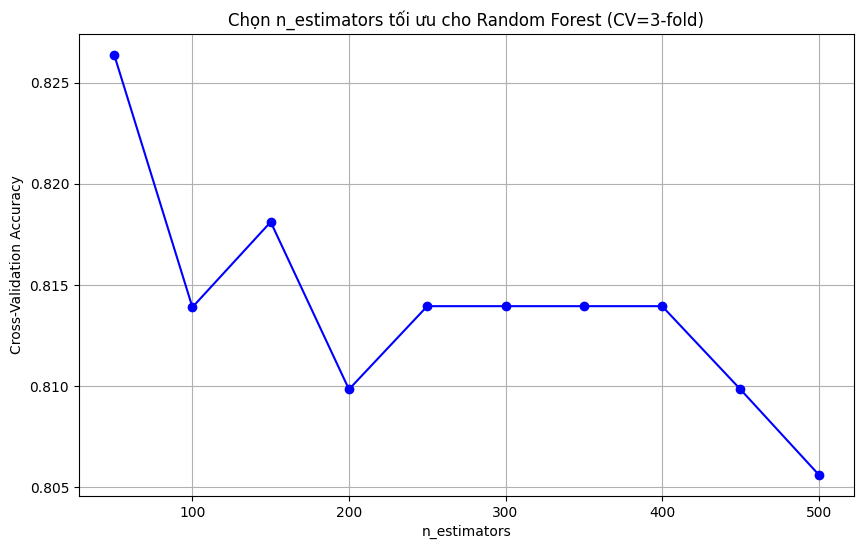


Độ chính xác Random Forest trên tập validation: 0.9667
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.94      0.97        16
           1       0.93      1.00      0.97        14

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Độ chính xác Random Forest trên tập test: 0.9032
Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.88      0.91        17
           1       0.87      0.93      0.90        14

    accuracy                           0.90        31
   macro avg       0.90      0.91      0.90        31
weighted avg       0.91      0.90      0.90        31



In [9]:
rf_model, val_acc, best_params = evaluate_val_rf(
    X_train, y_train, X_val, y_val)

test_acc = evaluate_test_rf(rf_model, X_test, y_test)

In [10]:
# Giữ lại Random Forest trên Original Dataset
rf_model_original = rf_model
rf_best_params_original = best_params.copy()

print("Saved Original Random Forest")
print("Best parameters:", rf_best_params_original)
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Saved Original Random Forest
Best parameters: {'n_estimators': 50}
Validation Accuracy: 0.9667
Test Accuracy: 0.9032


### 3.2 RF on Feature Engineering Dataset

Tìm n_estimators tối ưu cho Random Forest...
n_estimators tối ưu (CV): 200


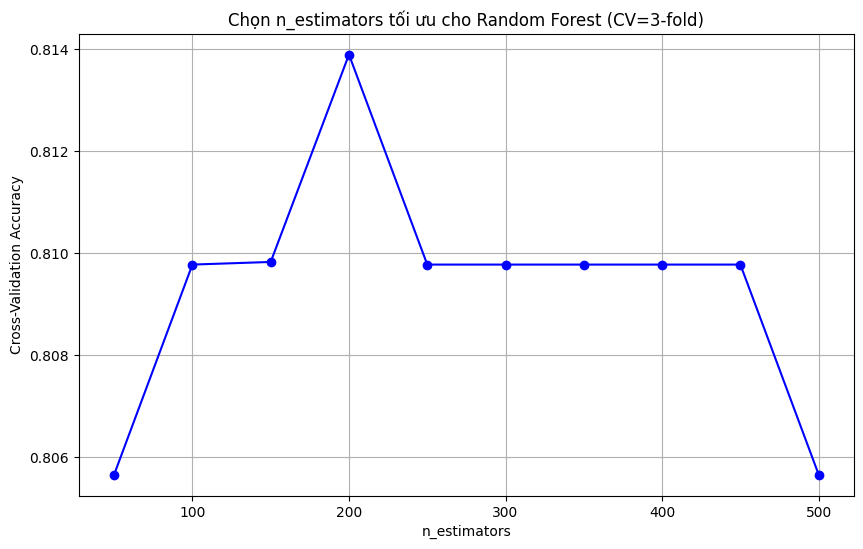


Độ chính xác Random Forest trên tập validation: 0.9000
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.81      0.90        16
           1       0.82      1.00      0.90        14

    accuracy                           0.90        30
   macro avg       0.91      0.91      0.90        30
weighted avg       0.92      0.90      0.90        30


Độ chính xác Random Forest trên tập test: 0.8710
Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.88      0.88        17
           1       0.86      0.86      0.86        14

    accuracy                           0.87        31
   macro avg       0.87      0.87      0.87        31
weighted avg       0.87      0.87      0.87        31



In [11]:
rf_model, val_fe_acc, best_params = evaluate_val_rf(
    X_fe_train, y_fe_train, X_fe_val, y_fe_val)

test_fe_acc = evaluate_test_rf(rf_model, X_fe_test, y_fe_test)

### 3.3 RF on Original DT Dataset

Tìm n_estimators tối ưu cho Random Forest...
n_estimators tối ưu (CV): 100


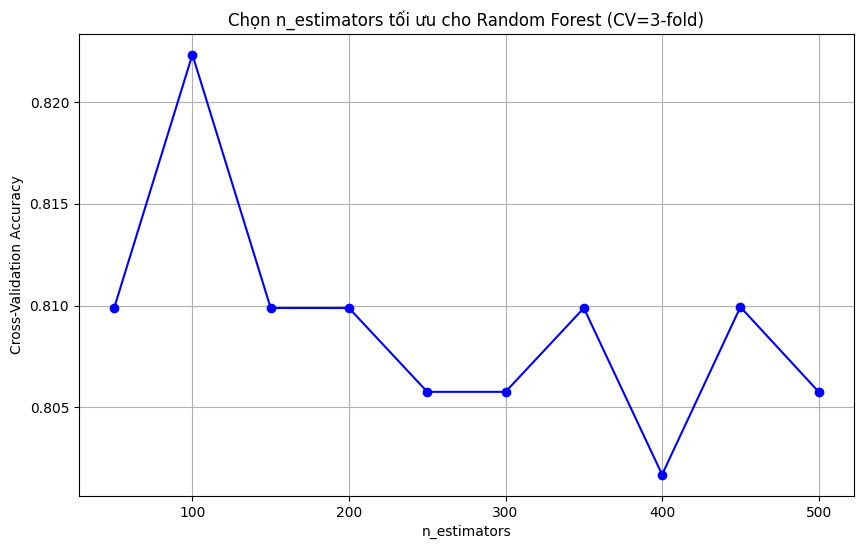


Độ chính xác Random Forest trên tập validation: 0.9667
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.94      0.97        16
           1       0.93      1.00      0.97        14

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Độ chính xác Random Forest trên tập test: 0.8387
Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.82      0.85        17
           1       0.80      0.86      0.83        14

    accuracy                           0.84        31
   macro avg       0.84      0.84      0.84        31
weighted avg       0.84      0.84      0.84        31



In [12]:
rf_model, val_dt_acc, best_params = evaluate_val_rf(
    X_dt_train, y_dt_train, X_dt_val, y_dt_val)

test_dt_acc = evaluate_test_rf(rf_model, X_dt_test, y_dt_test)

### 3.4 RF on Feature Engineering DT Dataset

Tìm n_estimators tối ưu cho Random Forest...
n_estimators tối ưu (CV): 300


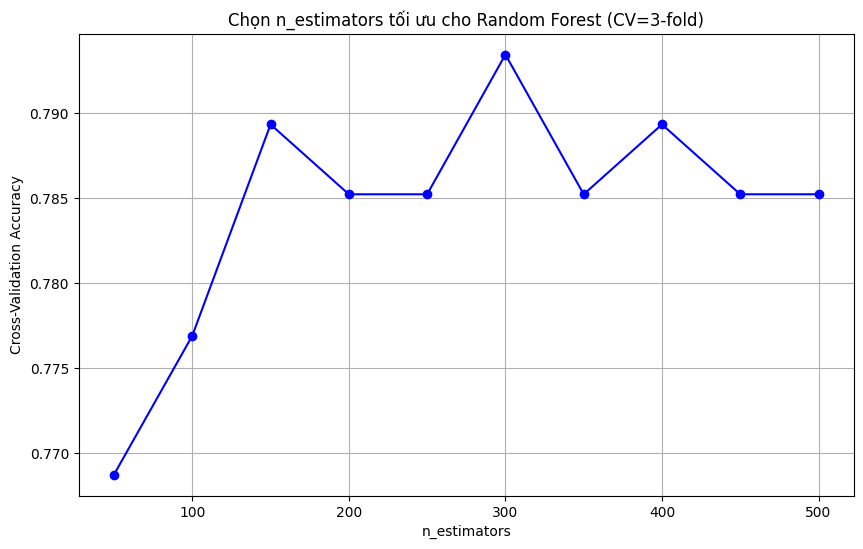


Độ chính xác Random Forest trên tập validation: 0.9333
Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94        16
           1       0.93      0.93      0.93        14

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Độ chính xác Random Forest trên tập test: 0.8387
Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.82      0.85        17
           1       0.80      0.86      0.83        14

    accuracy                           0.84        31
   macro avg       0.84      0.84      0.84        31
weighted avg       0.84      0.84      0.84        31



In [13]:
rf_model, val_fe_dt_acc, best_params = evaluate_val_rf(
    X_fe_dt_train, y_fe_dt_train, X_fe_dt_val, y_fe_dt_val)

test_fe_dt_acc = evaluate_test_rf(rf_model, X_fe_dt_test, y_fe_dt_test)

## 4.Result Visualization

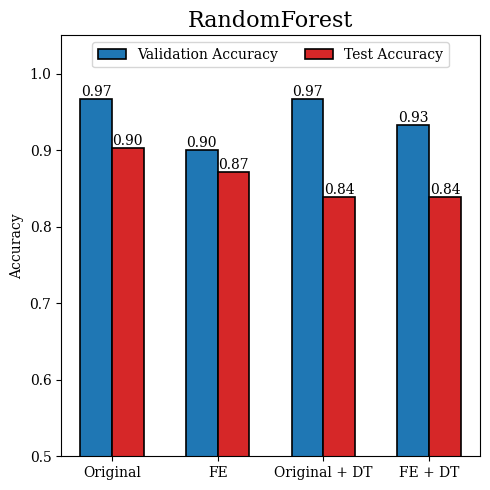

In [14]:
plt.rcParams['font.family'] = 'Serif'

labels = ['Original', 'FE', 'Original + DT', "FE + DT"]
val_accs = [val_acc, val_fe_acc, val_dt_acc, val_fe_dt_acc]
test_accs = [test_acc, test_fe_acc, test_dt_acc, test_fe_dt_acc]

x = np.arange(len(labels))
width = 0.3

fig, ax = plt.subplots(figsize=(5, 5))

rects1 = ax.bar(x - width/2, val_accs,  width,
                label='Validation Accuracy',
                color='tab:blue', edgecolor='black', linewidth=1.2)
rects2 = ax.bar(x + width/2, test_accs, width,
                label='Test Accuracy',
                color='tab:red', edgecolor='black', linewidth=1.2)

ax.set_ylim(0.5, 1.05)
ax.set_ylabel('Accuracy')
ax.set_title('RandomForest', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend(ncol=2, loc="upper center")

def autolabel(rects):
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f'{h:.2f}', xy=(rect.get_x()+rect.get_width()/2, h),
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
fig.savefig("accuracy_comparison.png", dpi=300, bbox_inches="tight")
fig.savefig("accuracy_comparison.pdf", bbox_inches="tight")
plt.show()


### Install and import

Reuse variables:
- `rf_model_original`
- `X_test`
- `y_test`

In [15]:
!pip -q install shap

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

print("SHAP version:", shap.__version__)

FIG_DIR = Path("Figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SHAP version: 0.52.0
All required variables are available.


### Compute SHAP values for the Disease class

For `sklearn.RandomForestClassifier` in binary classification, SHAP may return shape `(n_samples, n_features, 2)`, where output `0` = No Disease and output `1` = Disease.

In [16]:
X_shap = X_test.copy()
y_shap = y_test.copy()
model_shap = rf_model_original

explainer = shap.TreeExplainer(model_shap)
shap_values = explainer(X_shap)

print("Raw SHAP values shape:", shap_values.values.shape)

if shap_values.values.ndim == 3:
    shap_disease = shap_values[..., 1]
else:
    shap_disease = shap_values

print("Disease-class SHAP shape:", shap_disease.values.shape)
print("Number of samples:", shap_disease.shape[0])
print("Number of features:", shap_disease.shape[1])

Raw SHAP values shape: (31, 13, 2)
Disease-class SHAP shape: (31, 13)
Number of samples: 31
Number of features: 13


### Sanity check: SHAP additivity

In [17]:
sample_id = 0

pred_prob = model_shap.predict_proba(
    X_shap.iloc[[sample_id]]
)[0, 1]

shap_reconstructed = (
    shap_disease.base_values[sample_id]
    + shap_disease.values[sample_id].sum()
)

print(f"Model probability    : {pred_prob:.8f}")
print(f"SHAP reconstruction : {shap_reconstructed:.8f}")
print(
    f"Absolute difference : "
    f"{abs(pred_prob - shap_reconstructed):.10f}"
)

assert np.isclose(
    pred_prob,
    shap_reconstructed,
    atol=1e-6
)

print("SHAP additivity check: PASSED")

Model probability    : 0.98196404
SHAP reconstruction : 0.98196404
Absolute difference : 0.0000000000
SHAP additivity check: PASSED


### Global importance table

In [18]:
mean_abs_shap = np.abs(
    shap_disease.values
).mean(axis=0)

global_shap_importance = (
    pd.DataFrame({
        "feature": X_shap.columns,
        "mean_abs_shap": mean_abs_shap
    })
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

display(global_shap_importance)

global_shap_importance.to_csv(
    "treeshap_global_importance.csv",
    index=False
)

,feature,mean_abs_shap
0,cp,0.102052
1,thal,0.101839
2,ca,0.083801
3,oldpeak,0.062718
4,thalach,0.046916
5,exang,0.039041
6,sex,0.031361
7,slope,0.025544
8,age,0.023871
9,chol,0.017905


### Global bar plot

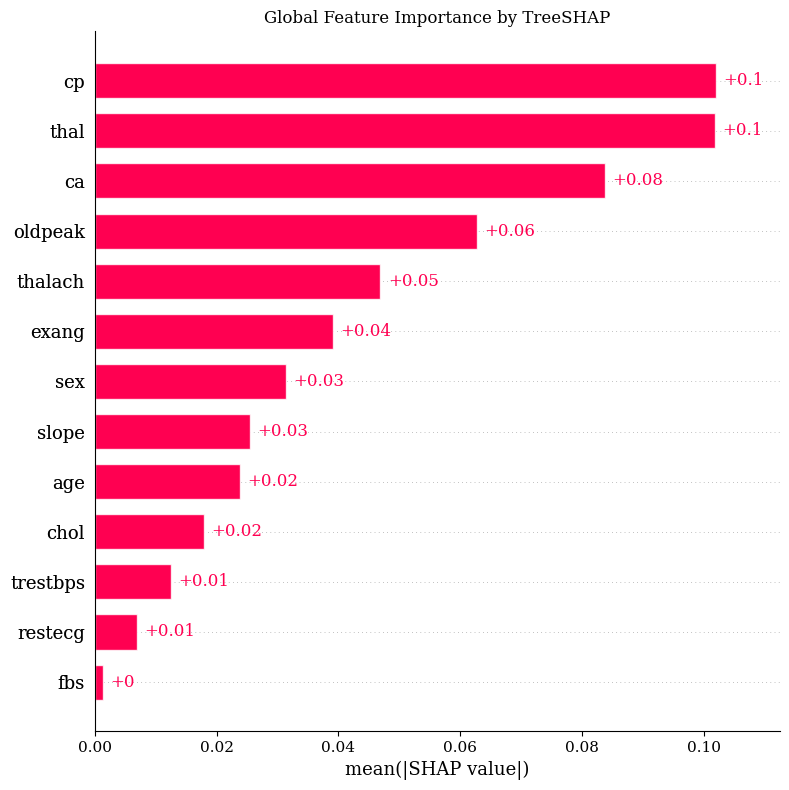

In [19]:
shap.plots.bar(
    shap_disease,
    max_display=min(13, X_shap.shape[1]),
    show=False
)

plt.title("Global Feature Importance by TreeSHAP")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "treeshap_global_bar.pdf",
    bbox_inches="tight"
)

plt.savefig(
    FIG_DIR / "treeshap_global_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Beeswarm plot

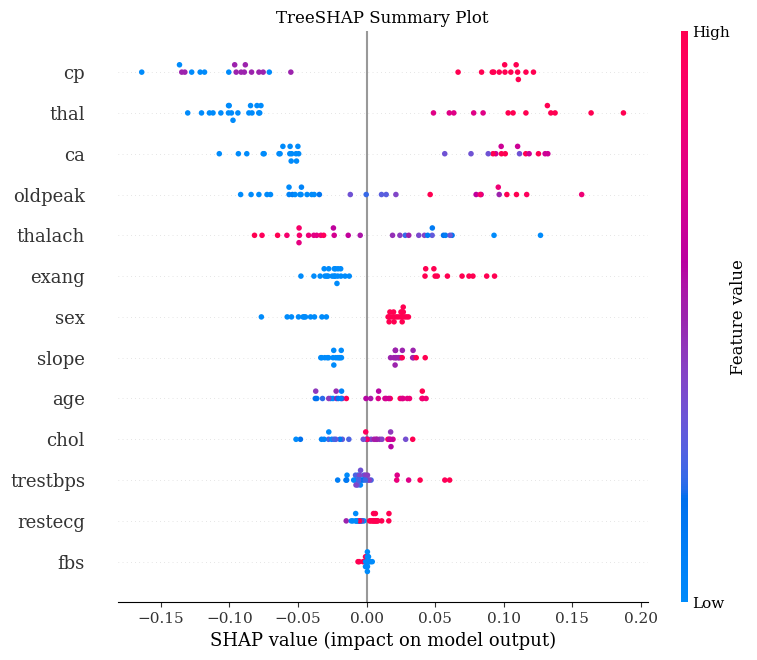

In [20]:
shap.plots.beeswarm(
    shap_disease,
    max_display=min(13, X_shap.shape[1]),
    show=False
)

plt.title("TreeSHAP Summary Plot")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "treeshap_beeswarm.pdf",
    bbox_inches="tight"
)

plt.savefig(
    FIG_DIR / "treeshap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Select a correctly predicted positive patient

In [21]:
test_pred = model_shap.predict(X_shap)
test_prob = model_shap.predict_proba(X_shap)[:, 1]

correct_positive = np.where(
    (y_shap.to_numpy() == 1)
    & (test_pred == 1)
)[0]

if len(correct_positive) > 0:
    local_id = correct_positive[
        np.argmax(test_prob[correct_positive])
    ]
else:
    local_id = int(np.argmax(test_prob))

print("Selected sample:", local_id)
print("Ground truth:", int(y_shap.iloc[local_id]))
print("Prediction:", int(test_pred[local_id]))
print("Disease probability:", f"{test_prob[local_id]:.4f}")

display(X_shap.iloc[[local_id]])

Selected sample: 0
Ground truth: 1
Prediction: 1
Disease probability: 0.9820


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal
0,0.384303,-0.16824,-0.641646,-0.837597,1.071575,1.0,1.0,0.0,1.0,1.0,0.5,1.0,1.0


### Local waterfall plot

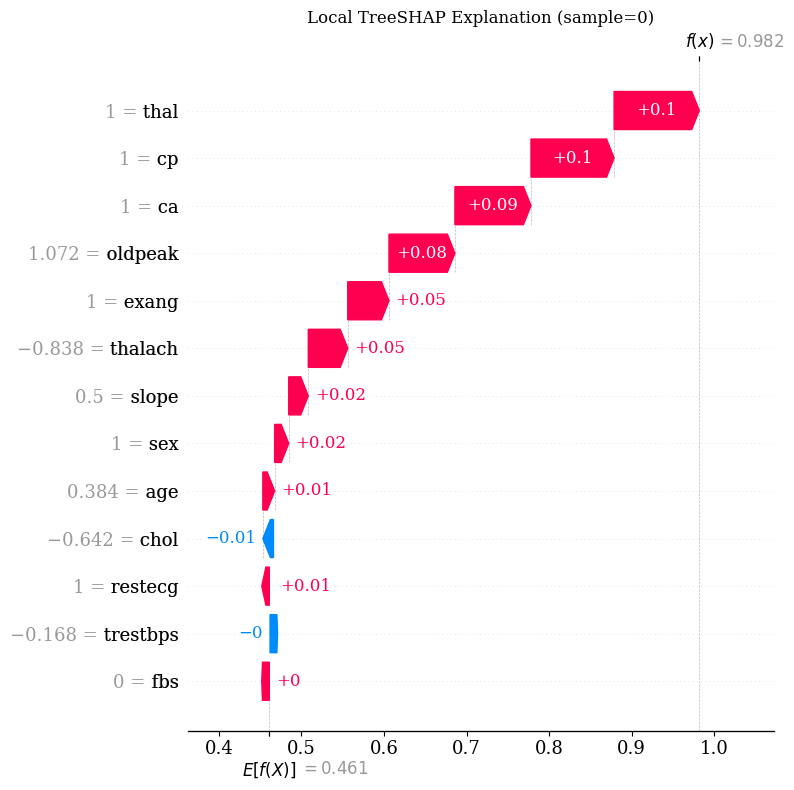

In [22]:
shap.plots.waterfall(
    shap_disease[local_id],
    max_display=min(13, X_shap.shape[1]),
    show=False
)

plt.title(
    f"Local TreeSHAP Explanation (sample={local_id})"
)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "treeshap_waterfall.pdf",
    bbox_inches="tight"
)

plt.savefig(
    FIG_DIR / "treeshap_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Find a misclassified case

In [23]:
wrong_ids = np.where(
    test_pred != y_shap.to_numpy()
)[0]

if len(wrong_ids) == 0:
    print("No misclassified sample was found on the test set.")
    wrong_id = None
else:
    wrong_id = int(wrong_ids[0])

    print("Misclassified sample:", wrong_id)
    print("Ground truth:", int(y_shap.iloc[wrong_id]))
    print("Prediction:", int(test_pred[wrong_id]))
    print("Disease probability:", f"{test_prob[wrong_id]:.4f}")

    display(X_shap.iloc[[wrong_id]])

Misclassified sample: 2
Ground truth: 0
Prediction: 1
Disease probability: 0.8576


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal
2,0.829818,-0.054513,-0.357219,-0.175039,0.714629,1.0,0.666667,0.0,0.0,0.0,0.5,1.0,1.0


### Waterfall for a misclassified case

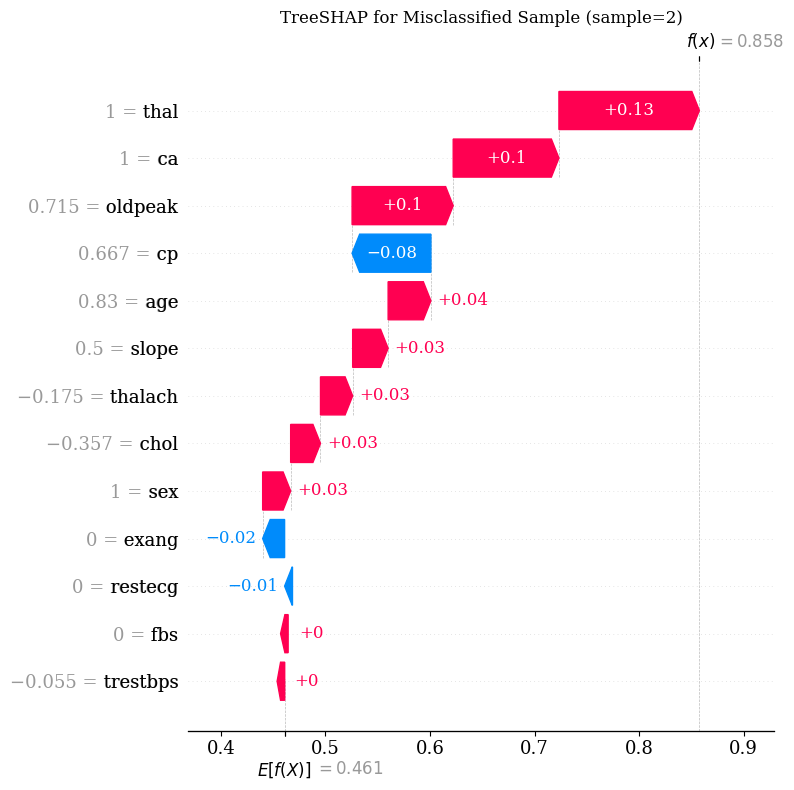

In [24]:
if wrong_id is not None:
    shap.plots.waterfall(
        shap_disease[wrong_id],
        max_display=min(13, X_shap.shape[1]),
        show=False
    )

    plt.title(
        f"TreeSHAP for Misclassified Sample (sample={wrong_id})"
    )
    plt.tight_layout()

    plt.savefig(
        FIG_DIR / "treeshap_misclassified_waterfall.pdf",
        bbox_inches="tight"
    )

    plt.savefig(
        FIG_DIR / "treeshap_misclassified_waterfall.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

### Compare Random Forest impurity importance vs TreeSHAP

In [25]:
importance_comparison = pd.DataFrame({
    "feature": X_shap.columns,
    "RF_impurity_importance": model_shap.feature_importances_,
    "TreeSHAP_mean_abs": np.abs(
        shap_disease.values
    ).mean(axis=0)
})

importance_comparison = (
    importance_comparison
    .sort_values(
        "TreeSHAP_mean_abs",
        ascending=False
    )
    .reset_index(drop=True)
)

display(importance_comparison)

importance_comparison.to_csv(
    "rf_importance_vs_treeshap.csv",
    index=False
)

,feature,RF_impurity_importance,TreeSHAP_mean_abs
0,cp,0.172093,0.102052
1,thal,0.164626,0.101839
2,ca,0.116217,0.083801
3,oldpeak,0.112693,0.062718
4,thalach,0.105900,0.046916
5,exang,0.061655,0.039041
6,sex,0.036985,0.031361
7,slope,0.042599,0.025544
8,age,0.056426,0.023871
9,chol,0.064800,0.017905
